In [1]:
# OpenCV library import karta hai (image processing ke liye)
import cv2

# Arrays aur numerical operations ke liye NumPy import karta hai
import numpy as np

# CSV aur tabular data handle karne ke liye Pandas import karta hai
import pandas as pd

# File aur folder operations ke liye os module import karta hai
import os

# Images aur graphs display karne ke liye Matplotlib import karta hai
import matplotlib.pyplot as plt

# Confirm karta hai ki sabhi libraries successfully load ho gayi hain
print("All libraries loaded!")

All libraries loaded!


In [2]:
# Layout features extract karne ke liye function define karta hai
def extract_layout_features(image_path):

    # Image load karta hai
    img = cv2.imread(image_path)

    # Image ko 224x224 size me resize karta hai
    img = cv2.resize(img, (224, 224))

    # Image ko grayscale me convert karta hai
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Image ki height aur width store karta hai
    h, w = gray.shape

    # Binary threshold apply karta hai taaki visual blocks detect ho sake
    # THRESH_BINARY_INV -> Dark regions white aur background black ban jata hai
    _, thresh = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY_INV)

    # Morphological kernel create karta hai
    kernel = np.ones((5, 5), np.uint8)

    # Nearby regions ko merge karne ke liye dilation apply karta hai
    thresh = cv2.dilate(thresh, kernel, iterations=2)

    # Image me contours (visual blocks) detect karta hai
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # Chhote noise contours remove karne ke liye minimum area define karta hai
    min_area = 100

    # Sirf valid contours ko filter karta hai
    valid_contours = [c for c in contours if cv2.contourArea(c) > min_area]

    # Total visual blocks count karta hai
    num_blocks = len(valid_contours)

    # Average block size calculate karta hai
    if num_blocks > 0:
        avg_block_size = round(np.mean([cv2.contourArea(c) for c in valid_contours]), 2)
    else:
        avg_block_size = 0

    # Sabhi blocks ka total area calculate karta hai
    total_block_area = sum(cv2.contourArea(c) for c in valid_contours)

    # Image me blocks ki density calculate karta hai
    block_density = round(total_block_area / (h * w) * 100, 2)

    # Left side ke blocks count karta hai
    left_blocks = sum(1 for c in valid_contours if cv2.boundingRect(c)[0] < w // 2)

    # Right side ke blocks count karta hai
    right_blocks = num_blocks - left_blocks

    # Left-Right balance calculate karta hai
    lr_balance = round(abs(left_blocks - right_blocks) / (num_blocks + 1e-5), 2)

    # Top side ke blocks count karta hai
    top_blocks = sum(1 for c in valid_contours if cv2.boundingRect(c)[1] < h // 2)

    # Bottom side ke blocks count karta hai
    bottom_blocks = num_blocks - top_blocks

    # Top-Bottom balance calculate karta hai
    tb_balance = round(abs(top_blocks - bottom_blocks) / (num_blocks + 1e-5), 2)

    # Chhote blocks ko text-like regions maanta hai
    text_like = sum(1 for c in valid_contours if cv2.contourArea(c) < 500)

    # Bade blocks ko image-like regions maanta hai
    image_like = sum(1 for c in valid_contours if cv2.contourArea(c) > 5000)

    # Layout ka clutter score calculate karta hai
    clutter_score = round((block_density * 0.5) + (text_like * 0.5), 2)

    # Sabhi layout features dictionary ke form me return karta hai
    return {
        'num_blocks': num_blocks,
        'avg_block_size': avg_block_size,
        'block_density': block_density,
        'lr_balance': lr_balance,
        'tb_balance': tb_balance,
        'text_like_regions': text_like,
        'image_like_regions': image_like,
        'clutter_score': clutter_score
    }

# Confirm karta hai ki layout feature extraction function define ho gaya hai
print("Layout feature extraction function defined!")

Layout feature extraction function defined!


In [3]:
# Images folder ka path define karta hai
IMAGES_DIR = r"C:\Projects\Internship_Learning\dataset\images"

# Images folder ki sabhi image files ki list leta hai
# Sirf valid image extensions wali files leta hai (folders/checkpoints ignore ho jate hain)
images = [f for f in os.listdir(IMAGES_DIR) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

# Pehli image ka complete path banata hai
test_image = os.path.join(IMAGES_DIR, images[0])

# Pehli image se layout features extract karta hai
features = extract_layout_features(test_image)

# Image ka naam print karta hai
print("Image:", images[0])

# Separator line print karta hai
print("-"*40)

# Sabhi extracted layout features aur unki values print karta hai
for feature, value in features.items():
    print(f"{feature:<25}: {value}")

Image: Screenshot 2026-06-23 132015.png
----------------------------------------
num_blocks               : 1
avg_block_size           : 47374.5
block_density            : 94.42
lr_balance               : 1.0
tb_balance               : 1.0
text_like_regions        : 0
image_like_regions       : 1
clutter_score            : 47.21


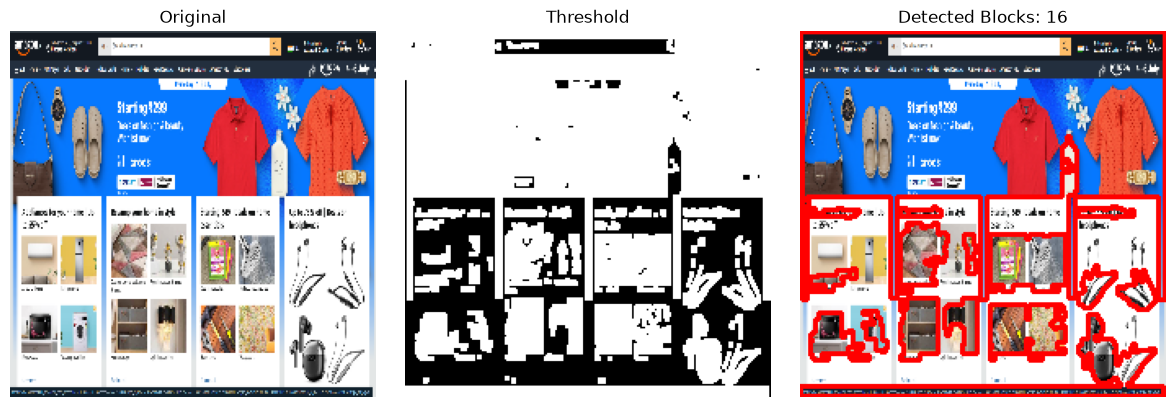

Total valid blocks: 16


In [4]:
# Visual blocks detect aur display karne ke liye function define karta hai
def visualize_blocks(image_path):

    # Image load karta hai
    img = cv2.imread(image_path)

    # Image ko 224x224 size me resize karta hai
    img = cv2.resize(img, (224, 224))

    # Image ko RGB format me convert karta hai
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Image ko grayscale me convert karta hai
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Binary threshold apply karta hai taaki visual blocks highlight ho sake
    _, thresh = cv2.threshold(gray, 180, 255, cv2.THRESH_BINARY_INV)

    # Morphological kernel create karta hai
    kernel = np.ones((3, 3), np.uint8)

    # Nearby regions ko merge karne ke liye dilation apply karta hai
    thresh = cv2.dilate(thresh, kernel, iterations=1)

    # Image me contours detect karta hai
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # Chhote noise contours remove karta hai
    valid_contours = [c for c in contours if cv2.contourArea(c) > 100]

    # Contours draw karne ke liye image ki copy banata hai
    img_contours = img_rgb.copy()

    # Valid contours ko image par draw karta hai
    cv2.drawContours(img_contours, valid_contours, -1, (255, 0, 0), 2)

    # Visualization ke liye figure create karta hai
    plt.figure(figsize=(12, 4))

    # Original image display karta hai
    plt.subplot(1, 3, 1)
    plt.imshow(img_rgb)
    plt.title("Original")
    plt.axis('off')

    # Threshold image display karta hai
    plt.subplot(1, 3, 2)
    plt.imshow(thresh, cmap='gray')
    plt.title("Threshold")
    plt.axis('off')

    # Detected blocks wali image display karta hai
    plt.subplot(1, 3, 3)
    plt.imshow(img_contours)
    plt.title(f"Detected Blocks: {len(valid_contours)}")
    plt.axis('off')

    # Layout automatically adjust karta hai
    plt.tight_layout()

    # Images display karta hai
    plt.show()

    # Total detected valid blocks print karta hai
    print("Total valid blocks:", len(valid_contours))

# Test image par function run karta hai
visualize_blocks(test_image)

In [5]:
# Updated layout feature extraction function define karta hai
def extract_layout_features(image_path):

    # Image load karta hai
    img = cv2.imread(image_path)

    # Image ko 224x224 size me resize karta hai
    img = cv2.resize(img, (224, 224))

    # Image ko grayscale me convert karta hai
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Image ki height aur width store karta hai
    h, w = gray.shape

    # Binary threshold apply karta hai taaki visual blocks detect ho sake
    _, thresh = cv2.threshold(gray, 180, 255, cv2.THRESH_BINARY_INV)

    # Morphological kernel create karta hai
    kernel = np.ones((3, 3), np.uint8)

    # Nearby regions ko merge karne ke liye dilation apply karta hai
    thresh = cv2.dilate(thresh, kernel, iterations=1)

    # Image me contours detect karta hai
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # Chhote noise contours remove karta hai
    valid_contours = [c for c in contours if cv2.contourArea(c) > 100]

    # Total visual blocks count karta hai
    num_blocks = len(valid_contours)

    # Average block size calculate karta hai
    avg_block_size = round(np.mean([cv2.contourArea(c) for c in valid_contours]), 2) if num_blocks > 0 else 0

    # Sabhi blocks ka total area calculate karta hai
    total_block_area = sum(cv2.contourArea(c) for c in valid_contours)

    # Block density calculate karta hai
    block_density = round(total_block_area / (h * w) * 100, 2)

    # Left side ke blocks count karta hai
    left_blocks = sum(1 for c in valid_contours if cv2.boundingRect(c)[0] < w // 2)

    # Right side ke blocks count karta hai
    right_blocks = num_blocks - left_blocks

    # Left-Right balance calculate karta hai
    lr_balance = round(abs(left_blocks - right_blocks) / (num_blocks + 1e-5), 2)

    # Top side ke blocks count karta hai
    top_blocks = sum(1 for c in valid_contours if cv2.boundingRect(c)[1] < h // 2)

    # Bottom side ke blocks count karta hai
    bottom_blocks = num_blocks - top_blocks

    # Top-Bottom balance calculate karta hai
    tb_balance = round(abs(top_blocks - bottom_blocks) / (num_blocks + 1e-5), 2)

    # Chhote blocks ko text-like regions maanta hai
    text_like = sum(1 for c in valid_contours if cv2.contourArea(c) < 500)

    # Bade blocks ko image-like regions maanta hai
    image_like = sum(1 for c in valid_contours if cv2.contourArea(c) > 5000)

    # Layout ka clutter score calculate karta hai
    clutter_score = round((block_density * 0.5) + (text_like * 0.5), 2)

    # Sabhi extracted layout features return karta hai
    return {
        'filename': os.path.basename(image_path),   # Sirf filename store karta hai
        'num_blocks': num_blocks,
        'avg_block_size': avg_block_size,
        'block_density': block_density,
        'lr_balance': lr_balance,
        'tb_balance': tb_balance,
        'text_like_regions': text_like,
        'image_like_regions': image_like,
        'clutter_score': clutter_score
    }

# Sabhi images ke features store karne ke liye list banata hai
all_features = []

# Folder ki har image ko process karta hai
for img_name in images:

    # Current image ka complete path banata hai
    img_path = os.path.join(IMAGES_DIR, img_name)

    # Current image se layout features extract karta hai
    features = extract_layout_features(img_path)

    # Features ko list me add karta hai
    all_features.append(features)

    # Processed image ka naam print karta hai
    print(f"Processed: {img_name}")

# Confirm karta hai ki sabhi images process ho gayi hain
print("\nAll images processed!")

Processed: Screenshot 2026-06-23 132015.png
Processed: Screenshot 2026-06-23 132334.png
Processed: Screenshot 2026-06-23 132939.png
Processed: Screenshot 2026-06-23 133431.png
Processed: Screenshot 2026-06-23 140930.png
Processed: Screenshot 2026-06-23 140957.png
Processed: Screenshot 2026-06-23 141031.png
Processed: Screenshot 2026-06-23 141056.png
Processed: Screenshot 2026-06-23 141120.png
Processed: Screenshot 2026-06-23 141744.png
Processed: Screenshot 2026-06-23 141920.png
Processed: Screenshot 2026-06-23 141947.png
Processed: Screenshot 2026-06-23 142025.png
Processed: Screenshot 2026-06-23 142056.png
Processed: Screenshot 2026-06-23 142134.png
Processed: Screenshot 2026-06-23 142153.png
Processed: Screenshot 2026-06-23 142813.png
Processed: Screenshot 2026-06-23 143059.png
Processed: Screenshot 2026-06-23 143140.png
Processed: Screenshot 2026-06-23 143213.png
Processed: Screenshot 2026-06-23 143230.png
Processed: Screenshot 2026-06-23 143250.png
Processed: Screenshot 2026-06-23

In [6]:
# Extracted layout features se DataFrame create karta hai
df_layout = pd.DataFrame(all_features)

# DataFrame ki first 5 rows display karta hai
print(df_layout.head())

# Total processed images (rows) print karta hai
print("\nTotal rows:", len(df_layout))

# CSV file save karne ka path define karta hai
csv_path = r"C:\Projects\Internship_Learning\dataset\layout_features.csv"

# DataFrame ko CSV file me save karta hai
# index=False -> Extra index column save nahi karta
df_layout.to_csv(csv_path, index=False)

# Confirm karta hai ki CSV successfully save ho gayi hai
print("\nlayout_features.csv saved!")

                           filename  num_blocks  avg_block_size  \
0  Screenshot 2026-06-23 132015.png          16         2039.47   
1  Screenshot 2026-06-23 132334.png          11         1954.32   
2  Screenshot 2026-06-23 132939.png           9         1208.06   
3  Screenshot 2026-06-23 133431.png          20          596.83   
4  Screenshot 2026-06-23 140930.png           6         2084.33   

   block_density  lr_balance  tb_balance  text_like_regions  \
0          65.03        0.37        0.50                  9   
1          42.84        0.09        0.45                  8   
2          21.67        0.11        0.11                  5   
3          23.79        0.30        0.10                 16   
4          24.92        1.00        0.33                  4   

   image_like_regions  clutter_score  
0                   1          37.02  
1                   1          25.42  
2                   1          13.34  
3                   0          19.89  
4                   1  